<a href="https://colab.research.google.com/github/Sinchanaar07/Portfolio/blob/main/ANN_digital_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Load the MNIST Dataset

In [ ]:
mnist = tf.keras.datasets.mnist

(x_train, y_train),(x_test, y_test) = mnist.load_data()

print("training images:",x_train.shape)
print("Training  labels:",y_train.shape)

print("Testing images:",x_test.shape)
print("Testing images:",y_test.shape)

training images: (60000, 28, 28)
Training  labels: (60000,)
Testing images: (10000, 28, 28)
Testing images: (10000,)


Display a handwritten image

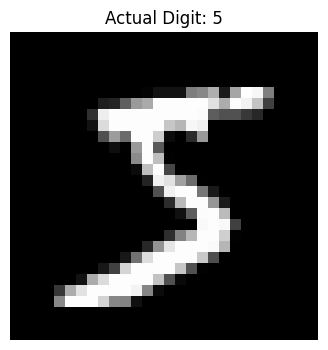

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis("off")
plt.show()

Normalize the pixel values

In [ ]:
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Minimum value:", x_train.min())
print("Maximum value:", x_train.max())

Minimum value: 0.0
Maximum value: 1.0


Build the BNN model

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9229 - loss: 0.2683 - val_accuracy: 0.9579 - val_loss: 0.1483
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9659 - loss: 0.1159 - val_accuracy: 0.9701 - val_loss: 0.0959
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9765 - loss: 0.0785 - val_accuracy: 0.9779 - val_loss: 0.0737
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9822 - loss: 0.0585 - val_accuracy: 0.9750 - val_loss: 0.0762
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9853 - loss: 0.0461 - val_accuracy: 0.9793 - val_loss: 0.0707


Evalaute the model

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9793 - loss: 0.0707
Test loss: 0.07071694731712341
Test Accuracy: 97.93000221252441 %


Predict a handwritten digit

In [ ]:
predictions = model.predict(x_test[:5])

for i in range(5):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    print(
        "Predicted:", predicted_digit,
        " | Actual:", actual_digit
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
Predicted: 7  | Actual: 7
Predicted: 2  | Actual: 2
Predicted: 1  | Actual: 1
Predicted: 0  | Actual: 0
Predicted: 4  | Actual: 4


Display Predicions

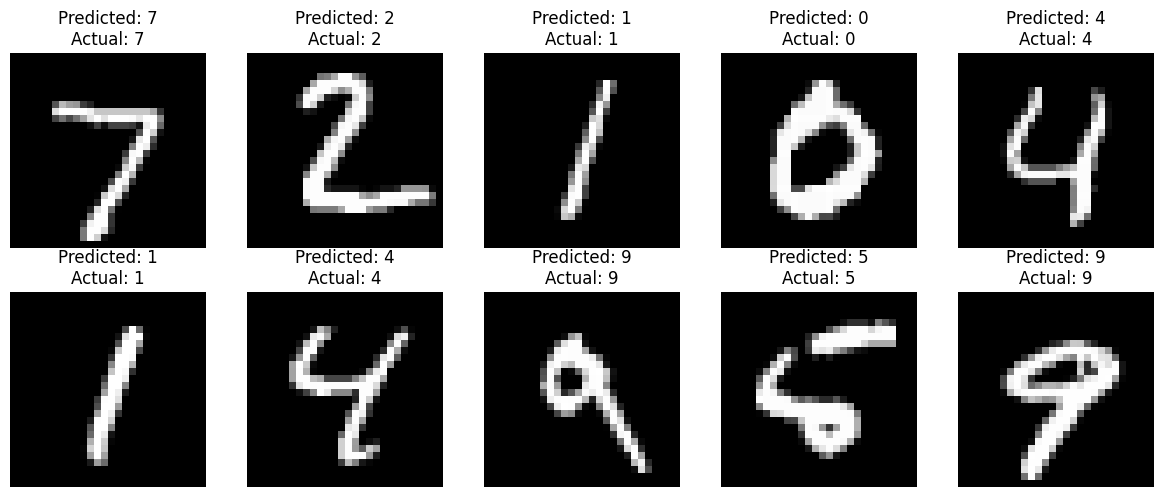

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    prediction = model.predict(
        x_test[i:i+1],
        verbose=0
    )

    predicted_digit = np.argmax(prediction)

    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Predicted: {predicted_digit}\nActual: {y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()